# Classification of Legal Text (US Supreme Court opinions)
**UE24CS352A Machine Learning - Mini-Project 5 - Team C-26 (Section C)**
Kshitij Satish Shetty (PES1UG24AM143) and Kushal G (PES1UG24AM145)

**Task:** predict the *issue area* (expert-labelled legal topic) of a Supreme Court opinion from its text.
**Dataset:** Supreme Court Database (~8.4k opinions, 1946-2016) as packaged by the `textacy` project, the same data used in the assigned reference report (Iyer, CS229 2020). Downloaded directly from its GitHub release.

**Reference paper:** LDA topics + Logistic Regression (baseline), Doc2Vec + Logistic Regression (best model), BERT (ran out of memory), plus a Doc2Vec similarity search.

**What this notebook adds on top of the reference paper**
1. A stronger, still CPU-only and explainable model: TF-IDF + linear models, chosen on a validation set.
2. The paper's own models re-implemented under the *same* leak-free split: LDA + LogReg **and Doc2Vec + LogReg**.
3. Leakage checks, 5-fold cross-validation (mean +- std instead of a single split), and error analysis.
4. A fine-grained experiment (issue codes) comparable to the paper's 279-label experiment.
5. The paper's "similar opinions" search (Roe v. Wade) with both TF-IDF and Doc2Vec.
6. A Streamlit demo, plus an auto-generated README so every number in it comes from this run.

**How to run:** `Runtime > Run all` (CPU is enough, roughly 20-30 minutes in total, mostly Doc2Vec). The data is downloaded automatically, so nothing needs uploading.
The last cell starts the Streamlit demo and keeps running, so run it manually when you need it.

## 0. Setup

In [1]:
!pip -q install streamlit gensim

Streamlit (demo) and gensim (Doc2Vec) are installed here. If Colab asks you to restart the runtime, restart it and then `Run all` again.

In [2]:
import os, re, json, time, warnings, zipfile, gzip, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")

# ---- Settings (change here only) ----
SEED = 42            # same seed => you and your teammate get identical results
MAX_CHARS = 30000    # use the first 30k characters of each opinion (keeps CPU time low)
MIN_CLASS_DOCS = 15  # drop classes with fewer documents than this (cannot be split/evaluated)
NGRAMS = (1, 1)      # single words only (light on memory). (1, 2) adds word pairs but needs much more RAM
RUN_LDA = True       # LDA topic baseline, mirrors the reference paper
RUN_DOC2VEC = True   # Doc2Vec + LogReg, the reference paper's best model (needs gensim)
D2V_CHARS = 10000    # Doc2Vec reads the first 10k characters (keeps CPU time reasonable)
D2V_DIM = 100        # embedding size
D2V_EPOCHS = 20
RUN_CV = True        # 5-fold cross-validation of the selected model
CV_FOLDS = 5
RUN_FINE_GRAINED = True   # issue-code (fine-grained) experiment, like the paper's 279-label one
MIN_FG_DOCS = 15          # keep issue codes with at least this many opinions

if RUN_DOC2VEC:
    try:
        from gensim.models.doc2vec import Doc2Vec, TaggedDocument
    except ImportError:
        print("gensim is not available -> Doc2Vec is skipped (restart the runtime after the pip install).")
        RUN_DOC2VEC = False

os.makedirs("results", exist_ok=True)
os.makedirs("model", exist_ok=True)

## 1. Load and inspect the dataset

In [3]:
# The dataset is the Supreme Court Database as packaged by the textacy project.
# We download the same file directly (no textacy install needed).
URL = ("https://github.com/bdewilde/textacy-data/releases/download/"
       "supreme_court_py3_v1.0/supreme-court-py3.json.gz")
DATA_FILE = "supreme-court-py3.json.gz"
if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(URL, DATA_FILE)
print("File size (MB):", round(os.path.getsize(DATA_FILE) / 1e6, 1))

with gzip.open(DATA_FILE, "rt", encoding="utf-8") as f:
    df = pd.DataFrame([json.loads(line) for line in f])

# issue_area code -> name (standard Supreme Court Database issue areas)
LABEL_NAMES = {1: "Criminal Procedure", 2: "Civil Rights", 3: "First Amendment", 4: "Due Process",
               5: "Privacy", 6: "Attorneys", 7: "Unions", 8: "Economic Activity", 9: "Judicial Power",
               10: "Federalism", 11: "Interstate Relations", 12: "Federal Taxation",
               13: "Miscellaneous", 14: "Private Action"}   # -1 = unlabeled

print("Rows:", len(df))
print("Columns:", list(df.columns))
df[["case_name", "issue", "issue_area", "decision_date"]].head(3)

File size (MB): 111.3
Rows: 8419
Columns: ['issue', 'issue_area', 'n_min_votes', 'case_name', 'text', 'maj_opinion_author', 'decision_date', 'decision_direction', 'n_maj_votes', 'us_cite_id', 'argument_date']


,case_name,issue,issue_area,decision_date
0,HALLIBURTON OIL WELL CEMENTING CO. v. WALKER e...,80180,8,1946-11-18
1,CLEVELAND v. UNITED STATES,10500,1,1946-11-18
2,CHAMPLIN REFINING CO. v. UNITED STATES ET AL.,80250,8,1946-11-18


,n_docs
issue_area,
Criminal Procedure,1924
Economic Activity,1667
Civil Rights,1360
Judicial Power,1149
First Amendment,658
Federalism,367
Unions,346
Due Process,335
Federal Taxation,304


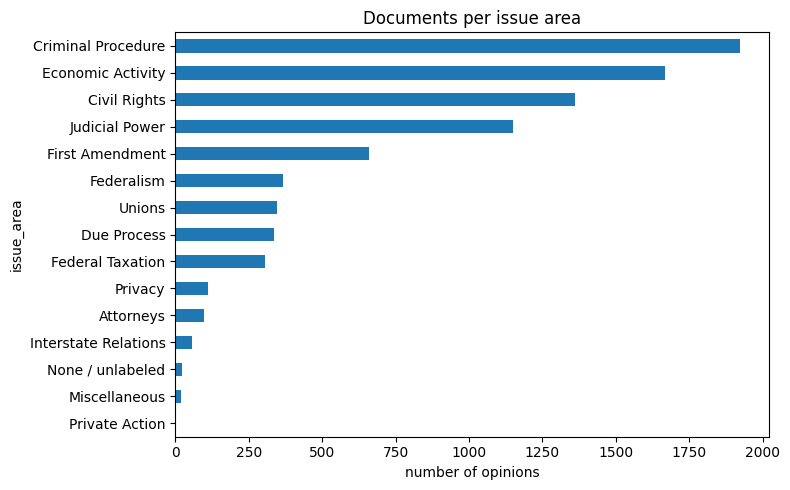

Approx. words per opinion:
count     8419.0
mean      6961.0
std       6274.0
min          1.0
25%       2826.0
50%       5552.0
75%       9366.0
max      87246.0
Name: text, dtype: float64
Very short texts (<500 chars): 73
Exact duplicate texts: 15


In [4]:
counts = df["issue_area"].map(lambda k: LABEL_NAMES.get(k, "None / unlabeled")).value_counts()
display(counts.to_frame("n_docs"))

ax = counts.sort_values().plot.barh(figsize=(8, 5))
ax.set_title("Documents per issue area"); ax.set_xlabel("number of opinions")
plt.tight_layout(); plt.savefig("results/class_distribution.png", dpi=150); plt.show()

print("Approx. words per opinion:")
print((df["text"].str.count(r"\s+") + 1).describe().round(0))
print("Very short texts (<500 chars):", (df["text"].str.len() < 500).sum())
print("Exact duplicate texts:", df["text"].duplicated().sum())

## 2. Clean the data
- remove empty/very short texts, unlabeled rows (`issue_area = -1`) and exact duplicate texts
- drop classes with too few documents to split and evaluate
- keep the first `MAX_CHARS` characters of each opinion

In [5]:
d = df.copy()
n_start = len(d)
d = d[d["text"].str.len() >= 500]
d = d[d["issue_area"] != -1]
d = d.drop_duplicates(subset="text")

vc = d["issue_area"].value_counts()
too_small = vc[vc < MIN_CLASS_DOCS]
d = d[d["issue_area"].isin(vc[vc >= MIN_CLASS_DOCS].index)].reset_index(drop=True)

print(f"Kept {len(d)} of {n_start} rows")
print("Dropped tiny classes:", {LABEL_NAMES.get(k, k): int(v) for k, v in too_small.items()})

X = d["text"].str[:MAX_CHARS]
y = d["issue_area"].astype(int).values
class_ids = sorted(np.unique(y))
class_names = [LABEL_NAMES[c] for c in class_ids]
print(len(class_ids), "classes:", class_names)
meta = d[["case_name", "issue", "issue_area", "decision_date"]].copy()   # aligned with X (same index)
N_RAW, N_CLEAN = n_start, len(d)

Kept 8328 of 8419 rows
Dropped tiny classes: {'Private Action': 1}
13 classes: ['Criminal Procedure', 'Civil Rights', 'First Amendment', 'Due Process', 'Privacy', 'Attorneys', 'Unions', 'Economic Activity', 'Judicial Power', 'Federalism', 'Interstate Relations', 'Federal Taxation', 'Miscellaneous']


## 3. Split first, then fit anything (prevents leakage)
Stratified 70% train / 15% validation / 15% test. The **validation** set is used to pick the model;
the **test** set is used once at the end.

In [6]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print("train / val / test sizes:", len(X_tr), len(X_val), len(X_te))

# Leakage check 1: no identical text appears in two splits
print("train∩val:", len(set(X_tr) & set(X_val)),
      " train∩test:", len(set(X_tr) & set(X_te)),
      " val∩test:", len(set(X_val) & set(X_te)))

train / val / test sizes: 5829 1249 1250
train∩val: 0  train∩test: 0  val∩test: 0


## 4. Features: TF-IDF (fit on TRAIN only)
Single words (unigrams), English stop-words removed, sub-linear term frequency.
The vectorizer learns its vocabulary and IDF weights from the training texts only; validation/test are only *transformed*.

In [7]:
tfidf = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=NGRAMS,
                        min_df=5, max_df=0.8, max_features=50000,
                        sublinear_tf=True, dtype=np.float32)
t0 = time.time()
Xtr = tfidf.fit_transform(X_tr)     # fit ONLY on train
Xva = tfidf.transform(X_val)
Xte = tfidf.transform(X_te)
print("TF-IDF matrix (train):", Xtr.shape, f"- {time.time()-t0:.0f}s")

TF-IDF matrix (train): (5829, 31568) - 27s


In [8]:
# Leakage check 2: shuffled-label test. If the model scores well above the majority
# class even when train labels are randomly shuffled, something is leaking.
shuf = LinearSVC(C=0.5, class_weight="balanced").fit(Xtr, np.random.RandomState(SEED).permutation(y_tr))
maj = pd.Series(y_tr).mode()[0]
print("Val accuracy with SHUFFLED labels:", round(accuracy_score(y_val, shuf.predict(Xva)), 3))
print("Val accuracy of always predicting the majority class:", round(np.mean(y_val == maj), 3))

Val accuracy with SHUFFLED labels: 0.167
Val accuracy of always predicting the majority class: 0.231


## 5. Train and compare models (choose on validation set)
Majority-class baseline, Logistic Regression, Linear SVM and Complement Naive Bayes, each with a couple of settings.
`class_weight="balanced"` handles the class imbalance. Macro-F1 (every class counts equally) is the selection metric.

In [9]:
def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0)}

candidates = {"Majority baseline": DummyClassifier(strategy="most_frequent")}
for C in [1, 10]:
    candidates[f"LogReg C={C}"] = LogisticRegression(C=C, class_weight="balanced", max_iter=300)
for C in [0.1, 0.5, 1]:
    candidates[f"LinearSVC C={C}"] = LinearSVC(C=C, class_weight="balanced")
for a in [0.1, 0.5]:
    candidates[f"ComplementNB alpha={a}"] = ComplementNB(alpha=a)

fitted, rows = {}, []
for name, model in candidates.items():
    t0 = time.time()
    model.fit(Xtr, y_tr)
    rows.append({"model": name, **scores(y_val, model.predict(Xva)), "fit_sec": round(time.time() - t0, 1)})
    fitted[name] = model

val_table = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).round(4).reset_index(drop=True)
best = val_table[val_table["model"] != "Majority baseline"].iloc[0]["model"]
display(val_table)
print("Selected on validation macro-F1:", best)

,model,accuracy,macro_f1,weighted_f1,fit_sec
0,LinearSVC C=0.5,0.7958,0.7322,0.7918,2.7
1,LinearSVC C=1,0.7958,0.7259,0.7917,3.1
2,LogReg C=10,0.7846,0.7107,0.7818,28.9
3,LogReg C=1,0.7646,0.6881,0.7636,13.6
4,LinearSVC C=0.1,0.7710,0.6834,0.7667,2.5
5,ComplementNB alpha=0.1,0.7222,0.5725,0.6966,0.1
6,ComplementNB alpha=0.5,0.7070,0.5218,0.6748,0.1
7,Majority baseline,0.2306,0.0288,0.0864,0.0


Selected on validation macro-F1: LinearSVC C=0.5


### Optional: LDA topics + Logistic Regression (the reference paper's baseline)

In [10]:
if RUN_LDA:
    t0 = time.time()
    cv = CountVectorizer(stop_words="english", min_df=10, max_df=0.5, max_features=10000, dtype=np.float32)
    Ctr = cv.fit_transform(X_tr); Cva = cv.transform(X_val); Cte = cv.transform(X_te)
    lda = LatentDirichletAllocation(n_components=25, learning_method="online", max_iter=10,
                                    batch_size=256, random_state=SEED, n_jobs=1)
    Ttr = lda.fit_transform(Ctr); Tva = lda.transform(Cva); Tte = lda.transform(Cte)
    lda_lr = LogisticRegression(C=10, class_weight="balanced", max_iter=1000).fit(Ttr, y_tr)
    lda_val = scores(y_val, lda_lr.predict(Tva))
    print("LDA validation:", {k: round(v, 4) for k, v in lda_val.items()},
          f"- {time.time()-t0:.0f}s")

LDA validation: {'accuracy': 0.554, 'macro_f1': 0.4457, 'weighted_f1': 0.5773} - 150s


### Doc2Vec + Logistic Regression (the reference paper's best model)
Doc2Vec turns each opinion into a fixed-size vector (PV-DBOW). To stay leak-free, Doc2Vec is **trained on the training opinions only**;
validation and test opinions are embedded with `infer_vector`, and the *same* inference step is applied to the training opinions so all three splits are embedded the same way.
Doc2Vec uses multiple threads, so expect small run-to-run differences.

In [11]:
D2V_OK = False
if RUN_DOC2VEC:
    t0 = time.time()
    def d2v_tokens(t):
        return re.findall(r"[a-z]{2,}", t[:D2V_CHARS].lower())

    tok_tr = [d2v_tokens(t) for t in X_tr]
    tok_va = [d2v_tokens(t) for t in X_val]
    tok_te = [d2v_tokens(t) for t in X_te]

    tagged = [TaggedDocument(w, [i]) for i, w in enumerate(tok_tr)]
    d2v = Doc2Vec(vector_size=D2V_DIM, dm=0, min_count=5, epochs=D2V_EPOCHS,
                  workers=max(1, os.cpu_count() or 1), seed=SEED)
    d2v.build_vocab(tagged)
    d2v.train(tagged, total_examples=d2v.corpus_count, epochs=d2v.epochs)
    print(f"Doc2Vec trained on TRAIN only - {time.time()-t0:.0f}s")

    def embed(token_lists):
        return np.vstack([d2v.infer_vector(w, epochs=D2V_EPOCHS) for w in token_lists])
    Dtr, Dva, Dte = embed(tok_tr), embed(tok_va), embed(tok_te)
    print(f"Embeddings ready {Dtr.shape} - {time.time()-t0:.0f}s")

    d2v_models, rows = {}, []
    for C in [1, 10]:
        m = LogisticRegression(C=C, class_weight="balanced", max_iter=2000).fit(Dtr, y_tr)
        d2v_models[C] = m
        rows.append({"model": f"Doc2Vec + LogReg C={C}", **scores(y_val, m.predict(Dva))})
    d2v_val = pd.DataFrame(rows).round(4)
    display(d2v_val)
    d2v_best_C = int(d2v_val.sort_values("macro_f1", ascending=False).iloc[0]["model"].split("C=")[1])
    d2v_lr = d2v_models[d2v_best_C]
    D2V_OK = True

Doc2Vec trained on TRAIN only - 169s
Embeddings ready (5829, 100) - 438s


,model,accuracy,macro_f1,weighted_f1
0,Doc2Vec + LogReg C=1,0.6757,0.6059,0.6830
1,Doc2Vec + LogReg C=10,0.6717,0.6015,0.6785


## 6. Final evaluation on the TEST set (used once)

In [12]:
test_rows = [("Majority baseline", fitted["Majority baseline"].predict(Xte)),
             (best, fitted[best].predict(Xte))]
if RUN_LDA:
    test_rows.append(("LDA(25 topics) + LogReg", lda_lr.predict(Tte)))
if D2V_OK:
    test_rows.append((f"Doc2Vec + LogReg (C={d2v_best_C})", d2v_lr.predict(Dte)))

test_table = pd.DataFrame([{"model": n, **scores(y_te, p)} for n, p in test_rows]).round(4)
display(test_table)
test_table.to_csv("results/test_metrics.csv", index=False)

# validation table with the paper's models appended (for the report)
extra = []
if RUN_LDA: extra.append({"model": "LDA(25 topics) + LogReg", **lda_val})
if D2V_OK: extra.extend(d2v_val.to_dict("records"))
val_all = pd.concat([val_table, pd.DataFrame(extra)], ignore_index=True).round(4)
val_all.to_csv("results/validation_metrics.csv", index=False)

pred = fitted[best].predict(Xte)
report = classification_report(y_te, pred, labels=class_ids, target_names=class_names, zero_division=0)
print(report)
open("results/classification_report.txt", "w").write(report)

,model,accuracy,macro_f1,weighted_f1
0,Majority baseline,0.2304,0.0288,0.0863
1,LinearSVC C=0.5,0.8176,0.7672,0.8156
2,LDA(25 topics) + LogReg,0.5816,0.4472,0.6118
3,Doc2Vec + LogReg (C=1),0.6696,0.5843,0.6761


                      precision    recall  f1-score   support

  Criminal Procedure       0.87      0.91      0.89       288
        Civil Rights       0.83      0.86      0.84       202
     First Amendment       0.90      0.80      0.84        99
         Due Process       0.64      0.58      0.61        50
             Privacy       0.83      0.62      0.71        16
           Attorneys       1.00      0.71      0.83        14
              Unions       0.77      0.98      0.86        52
   Economic Activity       0.82      0.80      0.81       250
      Judicial Power       0.72      0.69      0.70       167
          Federalism       0.80      0.71      0.75        55
Interstate Relations       0.78      0.88      0.82         8
    Federal Taxation       0.80      0.98      0.88        46
       Miscellaneous       0.50      0.33      0.40         3

            accuracy                           0.82      1250
           macro avg       0.79      0.76      0.77      1250
      

1056

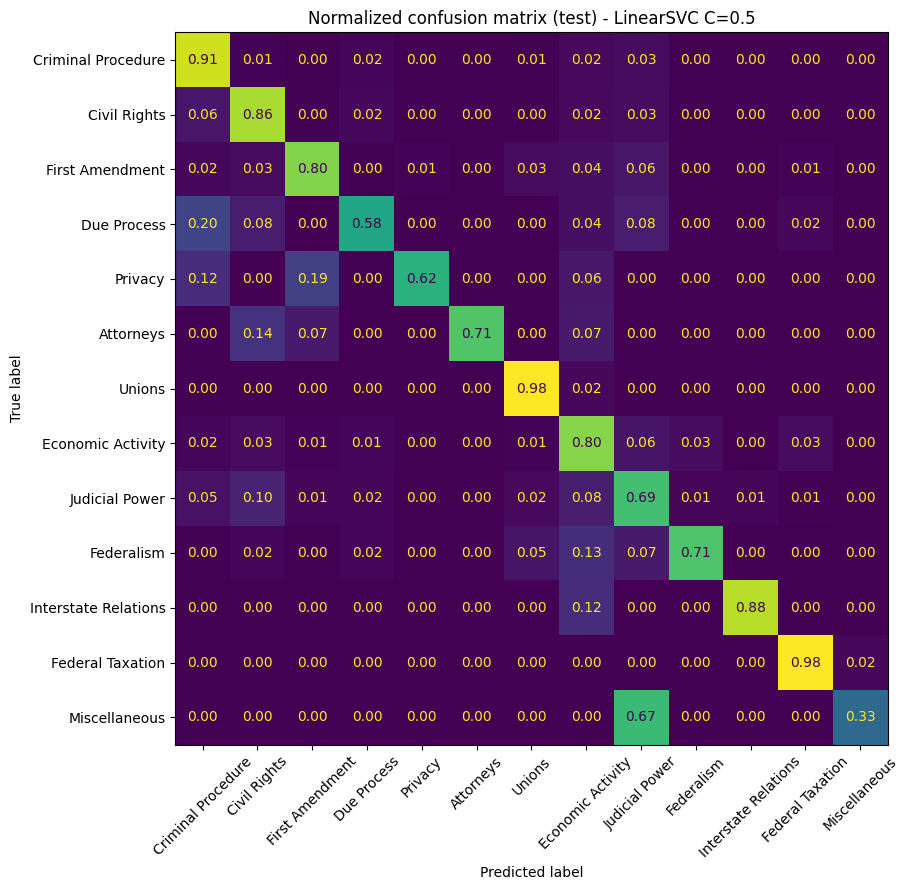

In [13]:
cm = confusion_matrix(y_te, pred, labels=class_ids, normalize="true")
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False, values_format=".2f")
ax.set_title(f"Normalized confusion matrix (test) - {best}")
plt.tight_layout(); plt.savefig("results/confusion_matrix.png", dpi=150); plt.show()

### How this compares with the reference paper
The paper (Iyer, CS229 2020) reports accuracy only. Its Table 1 has the column headers swapped: the text says LDA + LR gets 0.133 on the 279 issue codes and 0.47 on the 15 issue areas, so the table's columns are reversed.
Applying the same correction to the Doc2Vec row gives 0.63 (15 issue areas) and 0.48 (279 issue codes); this also matches the weighted average of the F1 scores in the paper's Table 2 (about 0.64).
**Caveat:** our label set and cleaning differ (13 issue areas after dropping a one-document class, 8,328 cleaned opinions), so the comparison is indicative, not exact.

In [14]:
paper = pd.DataFrame({
    "model": ["LDA + LogReg", "Doc2Vec + LogReg"],
    "paper: 15 issue areas (accuracy)": [0.47, 0.63],
    "paper: 279 issue codes (accuracy)": [0.13, 0.48],
})
display(paper)
print("Ours (13 issue areas, test accuracy):")
display(test_table[["model", "accuracy", "macro_f1"]])

,model,paper: 15 issue areas (accuracy),paper: 279 issue codes (accuracy)
0,LDA + LogReg,0.47,0.13
1,Doc2Vec + LogReg,0.63,0.48


Ours (13 issue areas, test accuracy):


,model,accuracy,macro_f1
0,Majority baseline,0.2304,0.0288
1,LinearSVC C=0.5,0.8176,0.7672
2,LDA(25 topics) + LogReg,0.5816,0.4472
3,Doc2Vec + LogReg (C=1),0.6696,0.5843


## 7. Explainability: which words drive each class?
For a linear model, each class has a weight per word. The highest-weight words show what the model learned.

In [15]:
feat = np.array(tfidf.get_feature_names_out())
m = fitted[best]
W = m.coef_ if hasattr(m, "coef_") else m.feature_log_prob_
top_terms = {LABEL_NAMES[c]: ", ".join(feat[np.argsort(W[i])[::-1][:10]]) for i, c in enumerate(m.classes_)}
top_df = pd.Series(top_terms).to_frame("top 10 terms")
pd.set_option("display.max_colwidth", None)
top_df.to_csv("results/top_terms.csv")
top_df

,top 10 terms
Criminal Procedure,"jury, search, jeopardy, bruton, sentencing, criminal, habeas, fourth, penalty, searches"
Civil Rights,"discrimination, indian, indigent, indians, tribe, immigration, deportation, equal, race, negroes"
First Amendment,"speech, religious, expression, religion, redrup, memoirs, freedom, beliefs, subversive, communist"
Due Process,"process, property, fifth, compensation, takings, taking, contacts, deprived, clause, fourteenth"
Privacy,"foia, abortion, disclosure, abortions, documents, clinics, privacy, clinic, information, records"
Attorneys,"fees, fee, award, prevailing, attorneys, hopkins, 1988, awards, disbarment, disbarred"
Unions,"labor, union, employees, 29, overtime, nlrb, dues, unions, laguardia, employer"
Economic Activity,"negligence, competition, liability, interstate, stock, pacific, injuries, antitrust, sherman, environmental"
Judicial Power,"improvidently, moot, dismissed, controversy, 28, venue, review, jurisdiction, action, dismiss"
Federalism,"empted, supremacy, emption, pre, state, preemption, garmon, empt, empts, arkansas"


## 7b. Error analysis
Which issue areas does the selected model confuse, and which opinions does it get wrong? (Useful for the report: many errors are between legally adjacent areas.)

In [16]:
err = pd.DataFrame({"case": meta.loc[X_te.index, "case_name"].str[:70].values,
                    "true": [LABEL_NAMES[c] for c in y_te],
                    "predicted": [LABEL_NAMES[c] for c in pred]})
wrong = err[err["true"] != err["predicted"]]
print(f"{len(wrong)} of {len(err)} test opinions misclassified")
pairs = (wrong.groupby(["true", "predicted"]).size().sort_values(ascending=False)
         .head(8).rename("count").reset_index())
display(pairs)
pairs.to_csv("results/top_confusions.csv", index=False)
display(wrong.sample(8, random_state=SEED).reset_index(drop=True))

228 of 1250 test opinions misclassified


,true,predicted,count
0,Judicial Power,Civil Rights,16
1,Economic Activity,Judicial Power,14
2,Judicial Power,Economic Activity,14
3,Civil Rights,Criminal Procedure,12
4,Due Process,Criminal Procedure,10
5,Criminal Procedure,Judicial Power,9
6,Economic Activity,Federal Taxation,8
7,Economic Activity,Federalism,8


,case,true,predicted
0,HINTON v. ALABAMA,Civil Rights,Criminal Procedure
1,"GREEN TREE FINANCIAL CORP., NKA CONSECO FINANCE CORP. v. LYNN W. BAZZL",Economic Activity,Federalism
2,"UNITED STATES v. LUCCHESE, ALIAS LUCKESE, ALIAS LUCASE, ALIAS ARRA, AL",Civil Rights,Judicial Power
3,UNITED STATES v. MUNOZ-FLORES,Federal Taxation,Miscellaneous
4,"CHAUFFEURS, TEAMSTERS AND HELPERS LOCAL NO. 391 v. TERRY et al.",Criminal Procedure,Unions
5,MUREL et al. v. BALTIMORE CITY CRIMINAL COURT et al.,Judicial Power,Due Process
6,UNITED STATES et al. v. FLORIDA EAST COAST RAILWAY CO. et al.,Judicial Power,Economic Activity
7,ATASCADERO STATE HOSPITAL et al. v. SCANLON,Federalism,Civil Rights


## 7c. Cross-validation (robustness check)
A single split can be lucky or unlucky, especially for small classes. Here the selected model is re-trained from scratch (TF-IDF included, so nothing leaks between folds)
on 5 stratified folds of the **train + validation** data. The test set is not touched.

In [17]:
cv_summary = None
if RUN_CV:
    t0 = time.time()
    X_cv = pd.concat([X_tr, X_val]); y_cv = np.concatenate([y_tr, y_val])
    cv_pipe = Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=NGRAMS, min_df=5,
                                  max_df=0.8, max_features=50000, sublinear_tf=True, dtype=np.float32)),
        ("clf", clone(fitted[best]))])
    skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    res = cross_validate(cv_pipe, X_cv, y_cv, cv=skf, n_jobs=1,
                         scoring={"accuracy": "accuracy", "macro_f1": "f1_macro", "weighted_f1": "f1_weighted"})
    cv_df = pd.DataFrame({k.replace("test_", ""): v for k, v in res.items() if k.startswith("test_")}).round(4)
    cv_df.index = [f"fold {i+1}" for i in range(len(cv_df))]
    display(cv_df)
    cv_summary = {m: (cv_df[m].mean(), cv_df[m].std()) for m in cv_df.columns}
    for m, (mu, sd) in cv_summary.items():
        print(f"{m}: {mu:.4f} +- {sd:.4f}")
    cv_df.to_csv("results/cross_validation.csv")
    print(f"{time.time()-t0:.0f}s")

,accuracy,macro_f1,weighted_f1
fold 1,0.7782,0.7420,0.7734
fold 2,0.8072,0.7392,0.8040
fold 3,0.8220,0.7298,0.8165
fold 4,0.8290,0.7932,0.8265
fold 5,0.8028,0.7274,0.7992


accuracy: 0.8078 +- 0.0197
macro_f1: 0.7463 +- 0.0269
weighted_f1: 0.8039 +- 0.0201
124s


## 7d. Fine-grained issue codes (comparable to the paper's 279-label experiment)
The same task one level deeper: predict the specific issue code instead of the broad issue area. Only codes with at least `MIN_FG_DOCS` opinions are kept, so the number of classes differs from the paper's 279.
Stratified 80/20 split; the best model type and C from the validation step above are reused (no extra tuning). Top-5 accuracy is reported too, since many codes are very close to each other.

In [18]:
fg_summary = None
if RUN_FINE_GRAINED:
    t0 = time.time()
    fg = df[(df["text"].str.len() >= 500) & (df["issue"] != -1)].drop_duplicates(subset="text")
    vc_fg = fg["issue"].value_counts()
    fg = fg[fg["issue"].isin(vc_fg[vc_fg >= MIN_FG_DOCS].index)].reset_index(drop=True)
    Xf, yf = fg["text"].str[:MAX_CHARS], fg["issue"].astype(int).values
    Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(Xf, yf, test_size=0.20, stratify=yf, random_state=SEED)

    tf_fg = clone(tfidf)
    A, B = tf_fg.fit_transform(Xf_tr), tf_fg.transform(Xf_te)
    maj_fg = DummyClassifier(strategy="most_frequent").fit(A, yf_tr)
    clf_fg = clone(fitted[best]).fit(A, yf_tr)
    p_fg = clf_fg.predict(B)

    top5 = np.nan
    if hasattr(clf_fg, "decision_function"):
        S = clf_fg.decision_function(B)
        top5_idx = np.argsort(S, axis=1)[:, -5:]
        top5 = float(np.mean([yf_te[i] in clf_fg.classes_[top5_idx[i]] for i in range(len(yf_te))]))

    fg_summary = {"n_docs": len(fg), "n_classes": len(np.unique(yf)),
                  "majority_acc": accuracy_score(yf_te, maj_fg.predict(B)),
                  "accuracy": accuracy_score(yf_te, p_fg),
                  "macro_f1": f1_score(yf_te, p_fg, average="macro", zero_division=0),
                  "top5_accuracy": top5}
    fg_df = pd.DataFrame([fg_summary]).round(4)
    display(fg_df)
    fg_df.to_csv("results/fine_grained_issue_codes.csv", index=False)
    print(f"{time.time()-t0:.0f}s")

,n_docs,n_classes,majority_acc,accuracy,macro_f1,top5_accuracy
0,7434,141,0.0323,0.7068,0.6556,0.9314


62s


## 7e. Finding similar opinions (the paper's Roe v. Wade search)
The paper uses Doc2Vec vectors as a search index. Here the same idea is tried with TF-IDF and with Doc2Vec: given one opinion, list its nearest neighbours by cosine similarity.
(Vectorizers/Doc2Vec were fitted on training data only; here they just *transform* the opinions.)

In [19]:
def find_case(sub):
    hits = d.index[d["case_name"].str.upper().str.contains(sub.upper(), regex=False)]
    return hits[0] if len(hits) else None

QUERY = "ROE ET AL. V. WADE"
q = find_case(QUERY)

def show_neighbours(sim, title, k=6):
    order = [i for i in np.argsort(sim)[::-1] if i != q][:k]
    out = pd.DataFrame({"case": d.loc[order, "case_name"].str[:65].values,
                        "year": d.loc[order, "decision_date"].astype(str).str[:4].values,
                        "issue area": [LABEL_NAMES[int(d.loc[i, "issue_area"])] for i in order],
                        "similarity": np.round(sim[order], 3)})
    print(f"{title} - query: {d.loc[q, 'case_name'][:60]} ({LABEL_NAMES[int(d.loc[q, 'issue_area'])]})")
    display(out)
    return out

if q is None:
    print("Query case not found in the cleaned data.")
else:
    Xall = tfidf.transform(X)
    sim_tfidf = (Xall @ Xall[q].T).toarray().ravel()
    s1 = show_neighbours(sim_tfidf, "TF-IDF similarity")
    s1.to_csv("results/similar_to_roe_tfidf.csv", index=False)

    if D2V_OK:
        D_all = np.zeros((len(d), D2V_DIM), dtype=np.float32)
        D_all[X_tr.index] = Dtr; D_all[X_val.index] = Dva; D_all[X_te.index] = Dte
        D_all /= np.linalg.norm(D_all, axis=1, keepdims=True) + 1e-9
        sim_d2v = D_all @ D_all[q]
        s2 = show_neighbours(sim_d2v, "Doc2Vec similarity")
        s2.to_csv("results/similar_to_roe_doc2vec.csv", index=False)

TF-IDF similarity - query: ROE et al. v. WADE, DISTRICT ATTORNEY OF DALLAS COUNTY (Privacy)


,case,year,issue area,similarity
0,"DOE et al. v. BOLTON, ATTORNEY GENERAL OF GEORGIA, et al.",1973,Privacy,0.404
1,"PLANNED PARENTHOOD OF CENTRAL MISSOURI et al. v. DANFORTH, ATTORN",1976,Privacy,0.338
2,CONNECTICUT v. MENILLO,1975,Privacy,0.302
3,"CITY OF AKRON v. AKRON CENTER FOR REPRODUCTIVE HEALTH, INC., et a",1983,Privacy,0.285
4,"SINGLETON, CHIEF, BUREAU OF MEDICAL SERVICES, DEPARTMENT OF HEALT",1976,Judicial Power,0.284
5,"COLAUTTI, SECRETARY OF WELFARE OF PENNSYLVANIA, et al. v. FRANKLI",1979,Privacy,0.280


Doc2Vec similarity - query: ROE et al. v. WADE, DISTRICT ATTORNEY OF DALLAS COUNTY (Privacy)


,case,year,issue area,similarity
0,"DOE et al. v. BOLTON, ATTORNEY GENERAL OF GEORGIA, et al.",1973,Privacy,0.718
1,"POE et al. v. ULLMAN, STATE'S ATTORNEY",1961,Judicial Power,0.643
2,"PLANNED PARENTHOOD OF CENTRAL MISSOURI et al. v. DANFORTH, ATTORN",1976,Privacy,0.627
3,"BOWERS, ATTORNEY GENERAL OF GEORGIA v. HARDWICK et al.",1986,Privacy,0.601
4,"H. L. v. MATHESON, GOVERNOR OF UTAH, et al.",1981,Privacy,0.593
5,"PLANNED PARENTHOOD ASSOCIATION OF KANSAS CITY, MISSOURI, INC., et",1983,Privacy,0.584


## 8. Save the model for the demo

In [20]:
tfidf.stop_words_ = None   # not needed for prediction; keeps the file small
pipe = Pipeline([("tfidf", tfidf), ("clf", fitted[best])])
assert (pipe.predict(X_te.iloc[:50]) == fitted[best].predict(Xte[:50])).all()

joblib.dump(pipe, "model/legal_clf.joblib", compress=3)
json.dump({str(c): LABEL_NAMES[c] for c in class_ids}, open("model/label_names.json", "w"))
json.dump({"max_chars": MAX_CHARS, "best_model": best, "seed": SEED}, open("model/config.json", "w"))

# a few held-out test opinions for the live demo
idx = np.random.RandomState(SEED).choice(len(X_te), 6, replace=False)
pd.DataFrame({"text": X_te.iloc[idx].values,
              "true_label": [LABEL_NAMES[y_te[i]] for i in idx],
              "model_prediction": [LABEL_NAMES[p] for p in pred[idx]]}).to_csv("model/samples.csv", index=False)

print("Model file size (MB):", round(os.path.getsize("model/legal_clf.joblib") / 1e6, 1))

Model file size (MB): 3.4


## 9. Streamlit app

In [21]:
%%writefile app.py
import json
import numpy as np
import pandas as pd
import joblib
import streamlit as st

st.set_page_config(page_title="Legal Text Classifier", layout="wide")


@st.cache_resource
def load():
    pipe = joblib.load("model/legal_clf.joblib")
    names = {int(k): v for k, v in json.load(open("model/label_names.json")).items()}
    cfg = json.load(open("model/config.json"))
    samples = pd.read_csv("model/samples.csv")
    return pipe, names, cfg, samples


pipe, names, cfg, samples = load()
tfidf, clf = pipe.named_steps["tfidf"], pipe.named_steps["clf"]

st.title("US Supreme Court Opinion Classifier")
st.caption(f"TF-IDF + {cfg['best_model']}. Predicts the issue area of a court opinion.")

options = ["(paste my own text)"] + [
    f"Held-out sample {i + 1} (true label: {r.true_label})" for i, r in samples.iterrows()
]
choice = st.selectbox("Start from a held-out test opinion, or paste your own", options)
default = "" if choice == options[0] else samples.loc[options.index(choice) - 1, "text"]
text = st.text_area("Opinion text", value=default, height=300)

if st.button("Classify") and text.strip():
    X = tfidf.transform([text[: cfg["max_chars"]]])
    if hasattr(clf, "predict_proba"):
        scores, kind = clf.predict_proba(X)[0], "Probability"
    else:
        d = clf.decision_function(X)[0]
        e = np.exp(d - d.max())
        scores, kind = e / e.sum(), "Relative score"

    order = np.argsort(scores)[::-1][:3]
    st.subheader(f"Predicted issue area: {names[int(clf.classes_[order[0]])]}")
    st.table(pd.DataFrame({
        "Issue area": [names[int(clf.classes_[i])] for i in order],
        kind: [round(float(scores[i]), 3) for i in order],
    }))

    coef = getattr(clf, "coef_", None)
    if coef is not None:
        contrib = X.multiply(coef[order[0]]).toarray().ravel()
        top = np.argsort(contrib)[::-1][:10]
        terms = tfidf.get_feature_names_out()[top]
        st.write("Words in this text that pushed the prediction most:", ", ".join(terms))

Writing app.py


## 10. Files for GitHub (README, requirements, .gitignore + zip)
The README is generated from the numbers computed in this run, so it always matches `results/`.
Do **not** commit your virtual environment (`venv/`) or the downloaded dataset: both are listed in `.gitignore`.

In [22]:
import importlib.metadata as im

def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(f"{v:.4f}" if isinstance(v, float) else str(v) for v in r.values) + " |")
    return "\n".join(lines)

reqs = ["streamlit", "scikit-learn", "pandas", "numpy", "joblib"]
def _ver(p):
    try:
        return f"{p}=={im.version(p)}"
    except im.PackageNotFoundError:
        return p
open("requirements.txt", "w").write("\n".join(_ver(p) for p in reqs) + "\n")
open(".gitignore", "w").write("venv/\n.venv/\n__pycache__/\n.ipynb_checkpoints/\n*.zip\nsupreme-court-py3.json.gz\ncloudflared\n")

sizes = f"{len(X_tr)} train / {len(X_val)} validation / {len(X_te)} test"
cv_line = ""
if cv_summary:
    cv_line = (f"{CV_FOLDS}-fold cross-validation of {best} on train+validation: accuracy "
               f"{cv_summary['accuracy'][0]:.3f} +- {cv_summary['accuracy'][1]:.3f}, macro-F1 "
               f"{cv_summary['macro_f1'][0]:.3f} +- {cv_summary['macro_f1'][1]:.3f}.")
fg_line = ""
if fg_summary:
    fg_line = (f"Fine-grained task ({fg_summary['n_classes']} issue codes, {fg_summary['n_docs']} opinions, 80/20 split): "
               f"accuracy {fg_summary['accuracy']:.3f}, top-5 accuracy {fg_summary['top5_accuracy']:.3f}, "
               f"macro-F1 {fg_summary['macro_f1']:.3f} (majority class: {fg_summary['majority_acc']:.3f}).")

readme = [
"# Classification of Legal Text: US Supreme Court Opinions",
"",
"UE24CS352A Machine Learning, Mini-Project 5, Team C-26 (Section C), PES University",
"",
"- Kshitij Satish Shetty (PES1UG24AM143)",
"- Kushal G (PES1UG24AM145)",
"",
"## Problem",
"",
"Given the text of a US Supreme Court opinion, predict its **issue area** (for example Criminal Procedure, Civil Rights, Federal Taxation), the legal topic assigned by expert coders in the Supreme Court Database. The assigned reference is the CS229 (2020) report by K. Iyer, which compares LDA + Logistic Regression, Doc2Vec + Logistic Regression and BERT.",
"",
"## Dataset",
"",
f"Supreme Court Database as packaged by the textacy project: {N_RAW} opinions (1946-2016) with full text and expert labels. The notebook downloads it automatically from the textacy-data GitHub release (about 111 MB), so nothing needs to be uploaded.",
"",
f"After cleaning (very short texts, unlabeled rows, exact duplicates and classes with fewer than {MIN_CLASS_DOCS} opinions removed) there are {N_CLEAN} documents in {len(class_ids)} classes. Only the first {MAX_CHARS} characters of each opinion are used. The split is stratified: {sizes} (seed {SEED}).",
"",
"## Approach",
"",
"- Features: TF-IDF on single words, fitted on the training split only.",
"- Models compared: majority-class baseline, Logistic Regression, Linear SVM, Complement Naive Bayes, and the reference paper's models re-implemented on the same split (LDA topics + Logistic Regression, Doc2Vec + Logistic Regression).",
"- Model selection by macro-F1 on the validation set. The test set is used once at the end.",
"- Leakage checks: split before fitting, no identical text across splits, shuffled-label test; Doc2Vec and LDA are trained on the training split only.",
f"- Robustness: {CV_FOLDS}-fold cross-validation, error analysis, a fine-grained issue-code experiment, and a similar-opinion search (Roe v. Wade) as in the reference paper.",
"",
"## Results (test set)",
"",
md_table(test_table),
"",
f"Selected model: **{best}**. " + cv_line,
"",
fg_line,
"",
"Full per-class report, confusion matrix, top confusions, cross-validation scores and top words per class are in `results/`.",
"",
"## Repository contents",
"",
"| Path | What it is |",
"|---|---|",
"| `Legal_Text_Classification_MiniProject.ipynb` | Full pipeline: data, cleaning, split, features, models, evaluation, export |",
"| `app.py` | Streamlit demo |",
"| `model/` | Saved pipeline (`legal_clf.joblib`), label names, config, held-out sample opinions |",
"| `results/` | Metrics tables, classification report, confusion matrix, cross-validation, similar-opinion lists, top terms |",
"| `requirements.txt` | Pinned versions for running the app |",
"",
"## How to run",
"",
"### 1. Train (Google Colab, CPU is enough)",
"",
"1. Open `Legal_Text_Classification_MiniProject.ipynb` in Google Colab (File > Upload notebook).",
"2. Choose Runtime > Run all (roughly 20-30 minutes; Doc2Vec is the slowest part). The first cell installs `streamlit` and `gensim`; if Colab asks to restart the runtime, restart and run all again. The last cell starts an optional tunnel for the demo, so it is fine to stop it.",
"3. The notebook writes `model/`, `results/`, `app.py`, `requirements.txt` and this README.",
"",
"### 2. Run the Streamlit demo locally",
"",
"```",
"python -m venv venv",
"venv\\Scripts\\activate          # Windows",
"# source venv/bin/activate     # macOS / Linux",
"pip install -r requirements.txt",
"python -m streamlit run app.py",
"```",
"",
"Open http://localhost:8501. Pick a held-out sample or paste an opinion, then click **Classify**. The app shows the top three predicted issue areas and the words that pushed the prediction most. The virtual environment is not part of the repository (see `.gitignore`).",
"",
"Note: the scores shown are a softmax of the SVM decision values, so they rank the classes but are not calibrated probabilities. The saved model was trained with the scikit-learn version pinned in `requirements.txt`, so use those versions.",
"",
"## Limitations",
"",
"The headline numbers come from a single split (cross-validation above shows the spread). The smallest classes have only a handful of test documents, so their per-class scores are noisy. Some top-weighted words are case names or numbers, so the model partly relies on case-specific vocabulary. Only the first part of each opinion is used, and no transformer model was trained (CPU-only; the reference paper's BERT run also ran out of memory). Our label set differs slightly from the paper's, so comparisons with its numbers are indicative.",
]
open("README.md", "w").write("\n".join(readme) + "\n")

with zipfile.ZipFile("project_files.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in ["README.md", "app.py", "requirements.txt", ".gitignore"]:
        z.write(f)
    for folder in ["model", "results"]:
        for fn in os.listdir(folder):
            z.write(os.path.join(folder, fn))
print(open("README.md").read())
try:
    from google.colab import files
    files.download("project_files.zip")
except ImportError:
    print("Not on Colab - project_files.zip is in the current folder.")

# Classification of Legal Text: US Supreme Court Opinions

UE24CS352A Machine Learning, Mini-Project 5, Team C-26 (Section C), PES University

- Kshitij Satish Shetty (PES1UG24AM143)
- Kushal G (PES1UG24AM145)

## Problem

Given the text of a US Supreme Court opinion, predict its **issue area** (for example Criminal Procedure, Civil Rights, Federal Taxation), the legal topic assigned by expert coders in the Supreme Court Database. The assigned reference is the CS229 (2020) report by K. Iyer, which compares LDA + Logistic Regression, Doc2Vec + Logistic Regression and BERT.

## Dataset

Supreme Court Database as packaged by the textacy project: 8419 opinions (1946-2016) with full text and expert labels. The notebook downloads it automatically from the textacy-data GitHub release (about 111 MB), so nothing needs to be uploaded.

After cleaning (very short texts, unlabeled rows, exact duplicates and classes with fewer than 15 opinions removed) there are 8328 documents in 13 classes. Only t

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. (Optional, run manually) Launch the demo inside Colab
This cell keeps running while the demo is open. Open the printed link; if it asks for a password, paste the IP shown.
For the live review it is more reliable to run the app on your own laptop: `pip install -r requirements.txt` then `streamlit run app.py`.

In [23]:
import subprocess, time
subprocess.run("pkill -f streamlit; pkill -f localtunnel", shell=True)
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(5)
!./cloudflared tunnel --url http://localhost:8501